# Synthetic Data Generation — EDA
Exploring the Adult Income dataset before generative modeling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

cols = ['age','workclass','fnlwgt','education','education_num','marital_status',
        'occupation','relationship','race','sex','capital_gain','capital_loss',
        'hours_per_week','native_country','income']

df = pd.read_csv('../data/adult.csv', header=None, names=cols,
                 na_values=' ?', skipinitialspace=True)
df.dropna(inplace=True)
df['income'] = df['income'].str.strip().map({'<=50K': 0, '>50K': 1})
print('Shape:', df.shape)
df.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [2]:
print('Numerical columns:', df.select_dtypes(include='number').columns.tolist())
print('Categorical columns:', df.select_dtypes(include='object').columns.tolist())
print('\nClass balance:')
print(df['income'].value_counts(normalize=True).round(3))

Numerical columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'income']
Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Class balance:
income
0    0.759
1    0.241
Name: proportion, dtype: float64


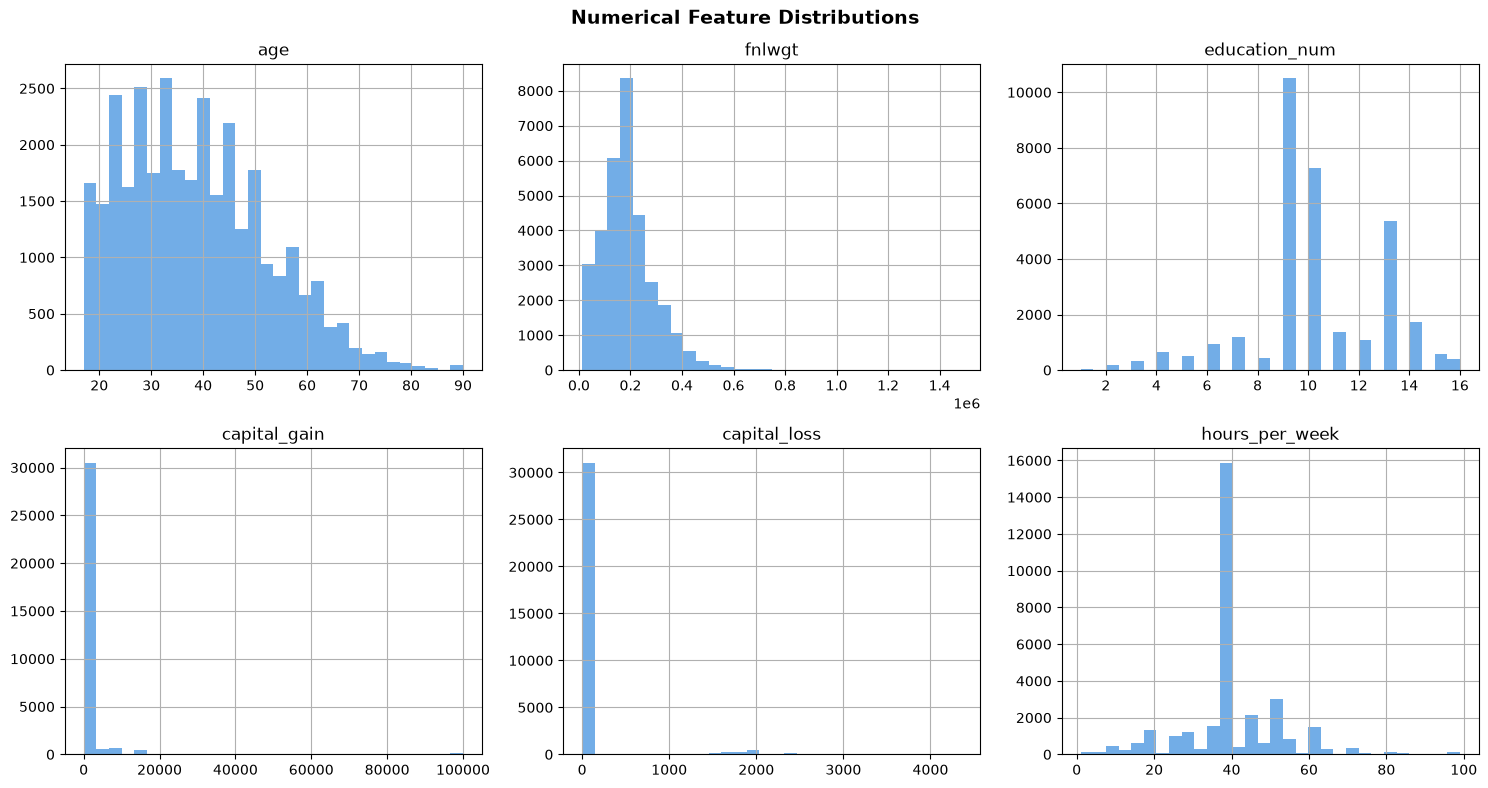

In [3]:
# Numerical distributions
num_cols = ['age','fnlwgt','education_num','capital_gain','capital_loss','hours_per_week']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    ax = axes[i//3][i%3]
    df[col].hist(bins=30, ax=ax, color='#378ADD', alpha=0.7)
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Numerical Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/numerical_dist.png', dpi=150, bbox_inches='tight')
plt.show()

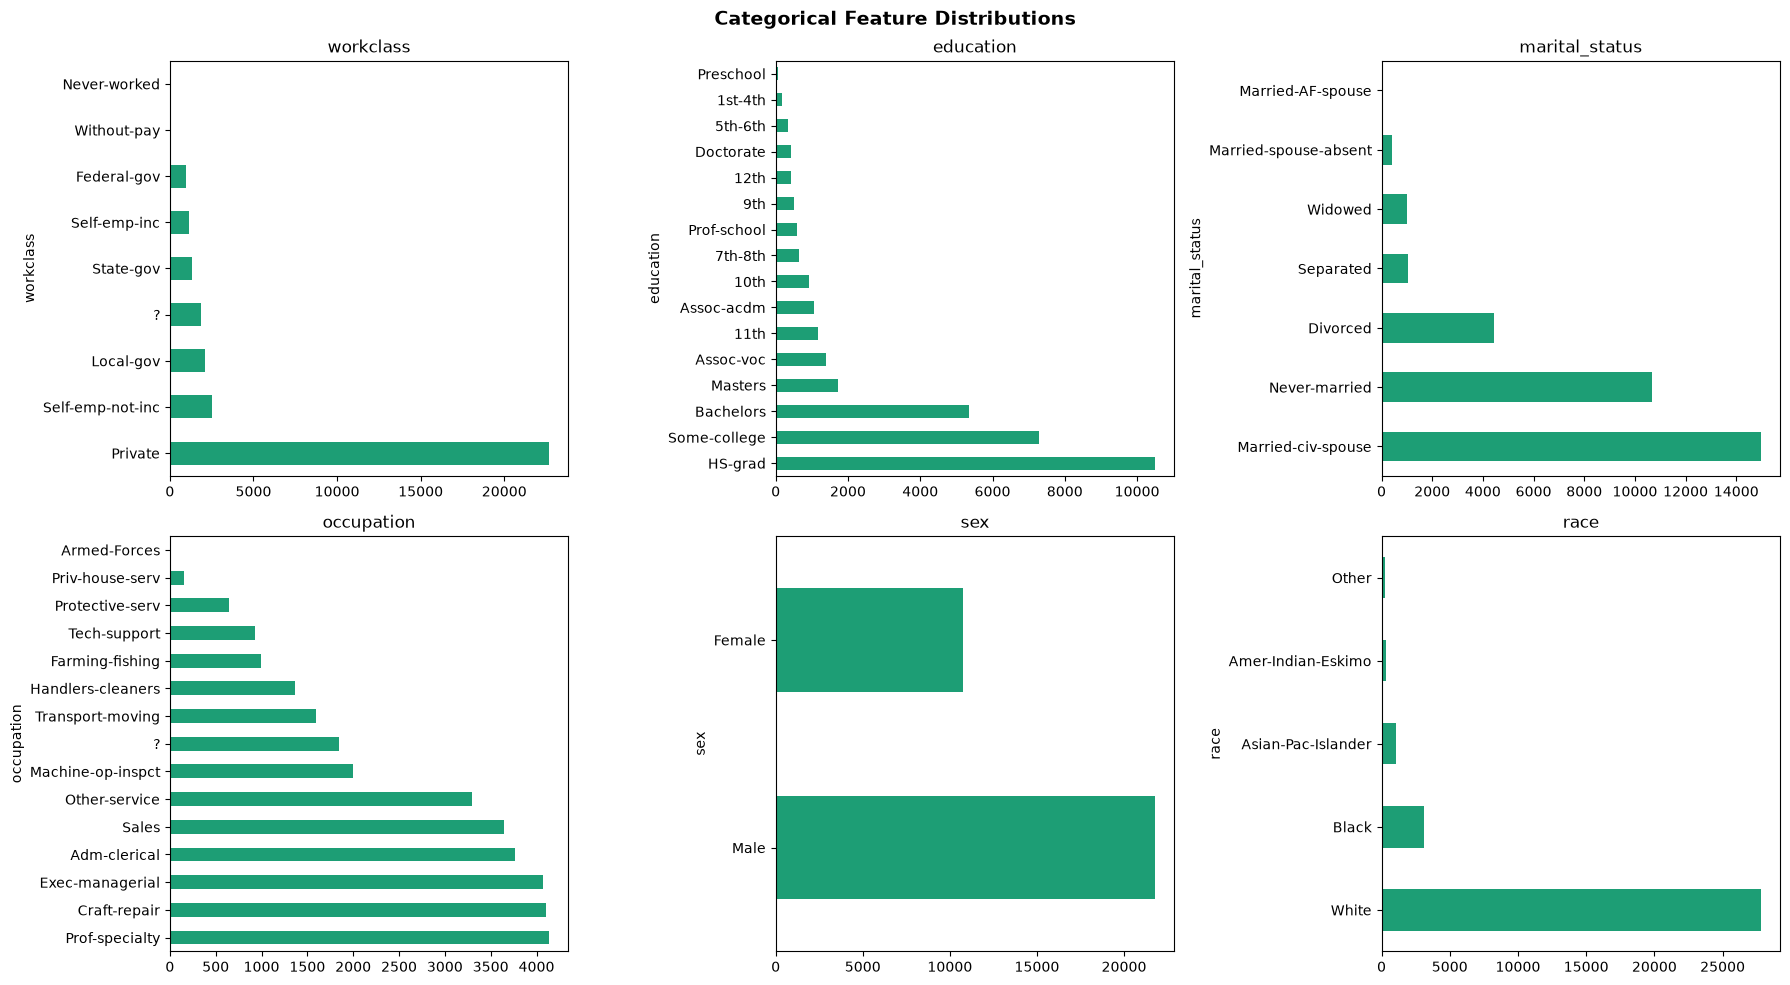

In [4]:
# Categorical distributions
cat_cols = ['workclass','education','marital_status','occupation','sex','race']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, col in enumerate(cat_cols):
    ax = axes[i//3][i%3]
    df[col].value_counts().plot(kind='barh', ax=ax, color='#1D9E75')
    ax.set_title(col)
plt.suptitle('Categorical Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/categorical_dist.png', dpi=150, bbox_inches='tight')
plt.show()

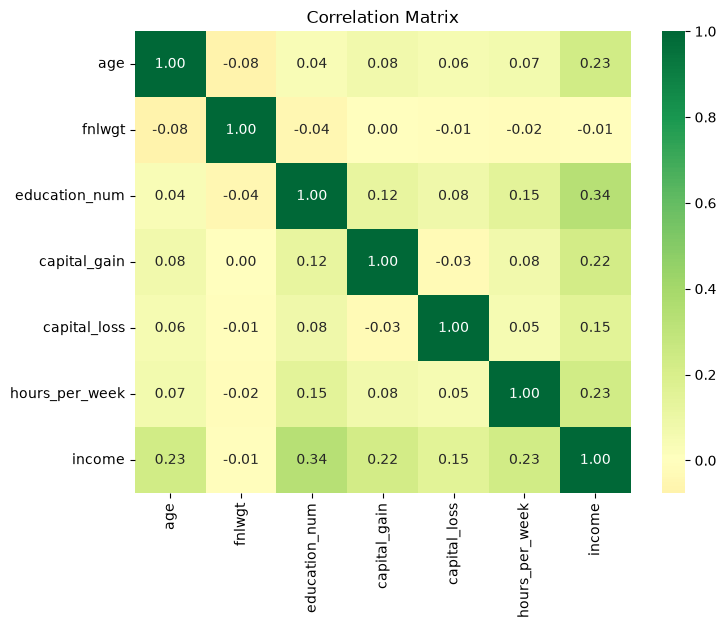

In [5]:
# Correlation matrix
plt.figure(figsize=(8, 6))
corr = df[num_cols + ['income']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.title('Correlation Matrix')
plt.savefig('../data/correlation.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Save cleaned data for modeling
df.to_csv('../data/adult_clean.csv', index=False)
print('Saved adult_clean.csv')
print('Shape:', df.shape)
print('\nKey stats:')
print(f'Income >50K: {df["income"].mean()*100:.1f}%')
print(f'Numerical cols: {len(num_cols)}')
print(f'Categorical cols: {len(cat_cols)}')

Saved adult_clean.csv
Shape: (32561, 15)

Key stats:
Income >50K: 24.1%
Numerical cols: 6
Categorical cols: 6
